# 3. Station clustering

Groups the 434 stations by usage pattern with k-means on four standardised features. The number of clusters is chosen from internal validity indices and checked against hierarchical clustering, DBSCAN and a structureless reference distribution.

**Input:** `../data/processed/TfL_Station_Features.csv`

**Output:** `../outputs/station_clustering_results.csv`, one labelled row per station.

## 3.1 Setup

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score,
    silhouette_samples,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score,
)

SEED = 123
PROCESSED = "../data/processed"
OUTPUTS = "../outputs"
os.makedirs(OUTPUTS, exist_ok=True)

FEATURES = [
    "LogMeanEntryCount",
    "CoefVariation",
    "Friday",
    "WeekdayWeekendBalance",
]

sns.set_theme(style="whitegrid")

sys.path.insert(0, "../src")
import tfl

In [2]:
features = pd.read_csv(f"{PROCESSED}/TfL_Station_Features.csv").set_index("Station")[FEATURES]

scaler = StandardScaler().set_output(transform="pandas")
X_scaled = scaler.fit_transform(features)

print(X_scaled.shape)
X_scaled.head()

(434, 4)


,LogMeanEntryCount,CoefVariation,Friday,WeekdayWeekendBalance
Station,,,,
Abbey Road DLR,-1.696704,0.484003,1.635769,0.701602
Abbey Wood,1.086952,-0.365772,-0.050404,0.107753
Acton Central,-0.825074,0.407444,1.515183,0.153677
Acton Main Line,-0.238221,-0.431983,0.309887,-0.153542
Acton Town,0.307167,-0.280369,0.585436,-0.289012


In [3]:
def to_real_units(values):
    """Undo the scaling and the log10 on volume so that centroids read in real units."""
    unscaled = scaler.inverse_transform(np.asarray(values))
    out = pd.DataFrame(unscaled, columns=FEATURES)
    out["LogMeanEntryCount"] = 10 ** out["LogMeanEntryCount"]
    out = out.rename(columns={"LogMeanEntryCount": "MeanEntryCount"})
    return out


X_real = to_real_units(X_scaled)
X_real.index = X_scaled.index

X_real.describe().round(3)

,MeanEntryCount,CoefVariation,Friday,WeekdayWeekendBalance
count,434.000,434.000,434.000,434.000
mean,8956.949,0.264,0.154,1.492
std,13337.296,0.076,0.007,0.375
min,197.611,0.133,0.118,0.760
25%,2442.360,0.212,0.150,1.290
50%,4754.878,0.247,0.155,1.444
75%,8805.199,0.300,0.158,1.613
max,105691.878,0.729,0.169,3.992


## 3.2 Is there discrete structure?

Explained variance ratio: [0.447 0.306 0.15  0.097]
Eigenvalues: [1.79 1.22 0.6  0.39]


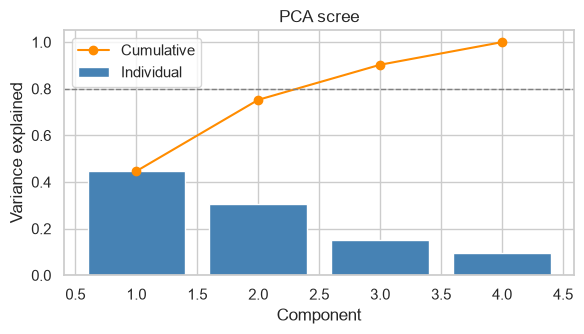

In [4]:
pca = PCA(n_components=None, random_state=SEED)
scores = pca.fit_transform(X_scaled)
evr = pca.explained_variance_ratio_

components = range(1, len(evr) + 1)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(components, evr, color="steelblue", label="Individual")
ax.plot(components, evr.cumsum(), "o-", color="darkorange", label="Cumulative")
ax.axhline(0.8, ls="--", lw=1, color="grey")
ax.set_xlabel("Component")
ax.set_ylabel("Variance explained")
ax.set_title("PCA scree")
ax.legend()
plt.tight_layout()

print("Explained variance ratio:", evr.round(3))
print("Eigenvalues:", (evr * len(FEATURES)).round(2))

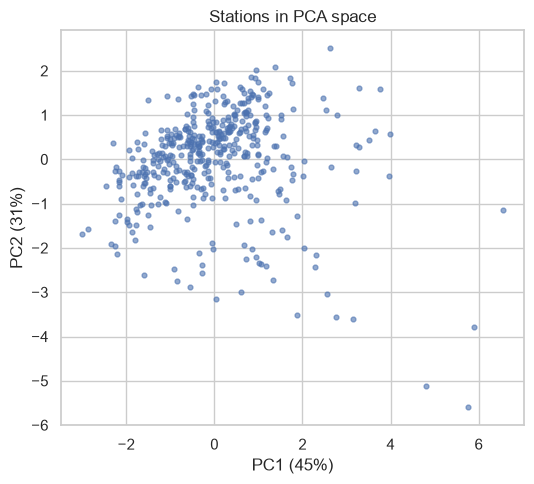

In [5]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(scores[:, 0], scores[:, 1], s=12, alpha=0.6)
ax.set_xlabel(f"PC1 ({evr[0]:.0%})")
ax.set_ylabel(f"PC2 ({evr[1]:.0%})")
ax.set_title("Stations in PCA space")
plt.tight_layout()

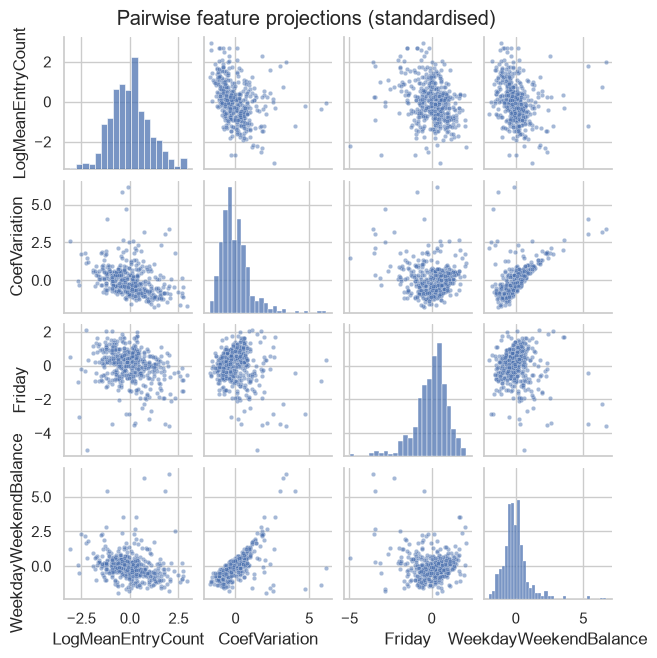

In [6]:
grid = sns.pairplot(X_scaled, plot_kws={"s": 10, "alpha": 0.5}, height=1.6)
grid.figure.suptitle("Pairwise feature projections (standardised)", y=1.02);

## 3.3 Choosing k

Inertia is expressed as variance explained. On standardised data the total inertia at k = 1 is `n * p`, so `1 - inertia_k / (n * p)` is the share of variance the partition accounts for.

In [7]:
def fit_kmeans(k):
    model = KMeans(n_clusters=k, init="k-means++", n_init=25, random_state=SEED)
    model.fit(X_scaled)
    return model

n_stations, n_features = X_scaled.shape
total_inertia = n_stations * n_features

rows = []
for k in range(2, 11):
    km = fit_kmeans(k)
    rows.append({
        "k": k,
        "inertia": km.inertia_,
        "var_explained": 1 - km.inertia_ / total_inertia,
        "silhouette": silhouette_score(X_scaled, km.labels_),
        "calinski_harabasz": calinski_harabasz_score(X_scaled, km.labels_),
        "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_)
    })

results = pd.DataFrame(rows)
results["marginal_gain"] = results["var_explained"].diff()

results.round(3)

,k,inertia,var_explained,silhouette,calinski_harabasz,davies_bouldin,marginal_gain
0,2,1282.067,0.261,0.265,152.956,1.393,NaN
1,3,979.893,0.436,0.282,166.285,1.198,0.174
2,4,864.354,0.502,0.227,144.543,1.306,0.067
3,5,751.612,0.567,0.234,140.466,1.150,0.065
4,6,668.903,0.615,0.246,136.557,1.081,0.048
5,7,598.006,0.656,0.245,135.429,1.095,0.041
6,8,537.328,0.690,0.240,135.760,1.086,0.035
7,9,496.166,0.714,0.237,132.750,1.113,0.024
8,10,468.980,0.730,0.225,127.278,1.097,0.016


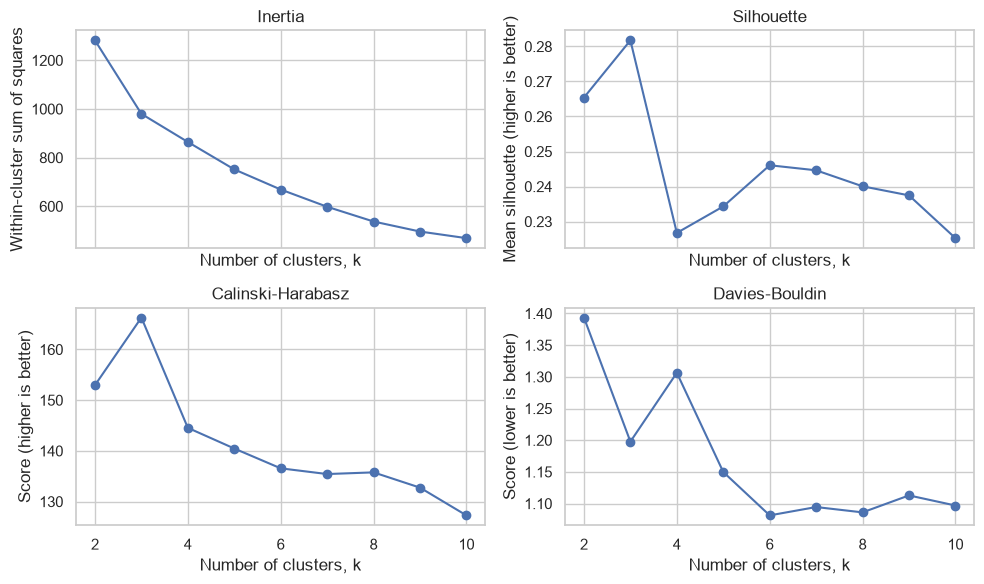

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True)

axes[0, 0].plot(results["k"], results["inertia"], "o-")
axes[0, 0].set_title("Inertia")
axes[0, 0].set_ylabel("Within-cluster sum of squares")

axes[0, 1].plot(results["k"], results["silhouette"], "o-")
axes[0, 1].set_title("Silhouette")
axes[0, 1].set_ylabel("Mean silhouette (higher is better)")

axes[1, 0].plot(results["k"], results["calinski_harabasz"], "o-")
axes[1, 0].set_title("Calinski-Harabasz")
axes[1, 0].set_ylabel("Score (higher is better)")

axes[1, 1].plot(results["k"], results["davies_bouldin"], "o-")
axes[1, 1].set_title("Davies-Bouldin")
axes[1, 1].set_ylabel("Score (lower is better)")

for ax in axes.flat:
    ax.set_xlabel("Number of clusters, k")

plt.tight_layout()

## 3.4 Silhouette by cluster

In [9]:
rows = []
for k in range(2, 11):
    km = fit_kmeans(k)
    sils = silhouette_samples(X_scaled, km.labels_)

    for station, cluster, sil in zip(X_scaled.index, km.labels_, sils):
        rows.append({"station": station, "k": k, "cluster": cluster, "sil": sil})

sil_df = pd.DataFrame(rows)

print(sil_df.shape)
sil_df.head()

(3906, 4)


,station,k,cluster,sil
0,Abbey Road DLR,2,0,0.301577
1,Abbey Wood,2,1,0.425113
2,Acton Central,2,0,0.238271
3,Acton Main Line,2,1,0.253006
4,Acton Town,2,1,0.352537


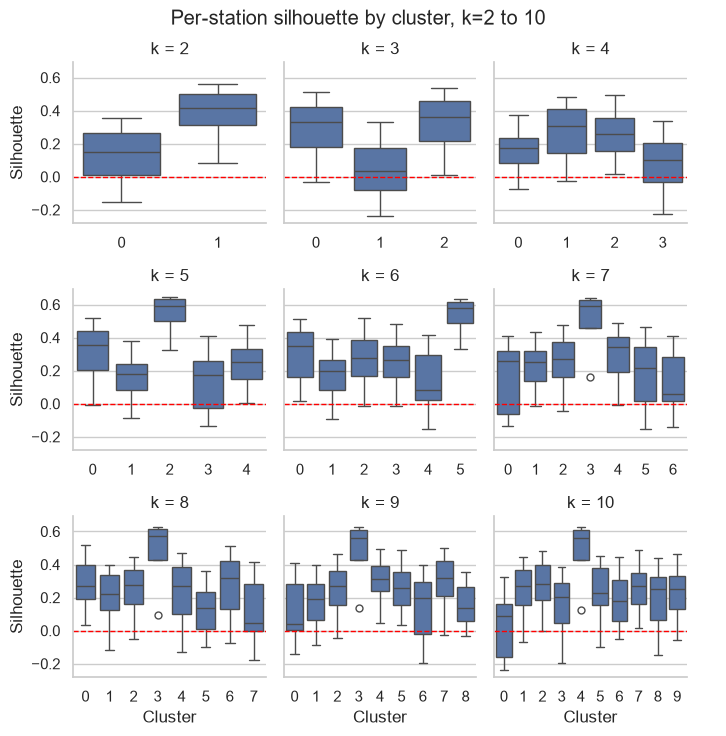

In [10]:
grid = sns.catplot(data=sil_df, x="cluster", y="sil", col="k", kind="box",
                   col_wrap=3, sharex=False, height=2.4)
grid.map(plt.axhline, y=0, color="red", ls="--", lw=1)
grid.set_axis_labels("Cluster", "Silhouette")
grid.figure.suptitle("Per-station silhouette by cluster, k=2 to 10", y=1.02);

In [11]:
# Very small clusters indicate that k-means is isolating outliers rather than
# dividing the bulk of the stations.
pd.crosstab(sil_df["cluster"], sil_df["k"])

k,2,3,4,5,6,7,8,9,10
cluster,,,,,,,,,
0,217,179,102,100,92,22,114,8,14
1,217,48,103,99,110,144,15,74,24
2,0,207,198,4,32,147,101,102,62
3,0,0,31,37,188,4,4,4,18
4,0,0,0,194,8,66,33,26,4
5,0,0,0,0,4,43,76,99,32
6,0,0,0,0,0,8,83,19,82
7,0,0,0,0,0,0,8,71,84
8,0,0,0,0,0,0,0,31,27


In [12]:
# Label numbers are arbitrary between fits, so the commuter cluster is identified
# at each k as the one with the highest weekday-to-weekend balance.
def commuter_label(k):
    centres = pd.DataFrame(fit_kmeans(k).cluster_centers_, columns=FEATURES)
    return centres["WeekdayWeekendBalance"].idxmax()

commuter_k3 = sil_df.query("k == 3 and cluster == @commuter_label(3)")["station"]
commuter_k4 = sil_df.query("k == 4 and cluster == @commuter_label(4)")["station"]

shared = set(commuter_k3) & set(commuter_k4)

print(f"k=3 commuter cluster: {len(commuter_k3)} stations")
print(f"k=4 commuter cluster: {len(commuter_k4)} stations")
print(f"Shared: {len(shared)}")

k=3 commuter cluster: 48 stations
k=4 commuter cluster: 31 stations
Shared: 31


## 3.5 k = 3 against k = 4

In [13]:
km_3 = fit_kmeans(3)
km_4 = fit_kmeans(4)

print("k=3 sizes:", np.bincount(km_3.labels_))
print("k=4 sizes:", np.bincount(km_4.labels_))

k=3 sizes: [179  48 207]
k=4 sizes: [102 103 198  31]


In [14]:
print("k=3 centroids (real units)")
display(to_real_units(km_3.cluster_centers_).round(3))

print("k=4 centroids (real units)")
display(to_real_units(km_4.cluster_centers_).round(3))

k=3 centroids (real units)


,MeanEntryCount,CoefVariation,Friday,WeekdayWeekendBalance
0,10620.791,0.212,0.152,1.273
1,4361.230,0.390,0.143,2.063
2,2626.770,0.279,0.158,1.549


k=4 centroids (real units)


,MeanEntryCount,CoefVariation,Friday,WeekdayWeekendBalance
0,1872.631,0.321,0.158,1.756
1,18188.745,0.205,0.151,1.238
2,3886.449,0.242,0.155,1.399
3,7386.927,0.404,0.139,2.062


In [15]:
km3_profile = X_scaled.copy()
km3_profile["cluster"] = km_3.labels_

km3_profile.groupby("cluster").agg(["mean", "std", "count"]).round(2)

LogMeanEntryCount             CoefVariation             Friday        \
                     mean   std count          mean   std count   mean   std   
cluster                                                                        
0                    0.73  0.81   179         -0.69  0.52   179  -0.24  0.67   
1                   -0.12  1.14    48          1.68  1.34    48  -1.49  1.36   
2                   -0.60  0.64   207          0.20  0.59   207   0.55  0.65   

              WeekdayWeekendBalance              
        count                  mean   std count  
cluster                                          
0         179                 -0.58  0.48   179  
1          48                  1.52  1.75    48  
2         207                  0.15  0.59   207

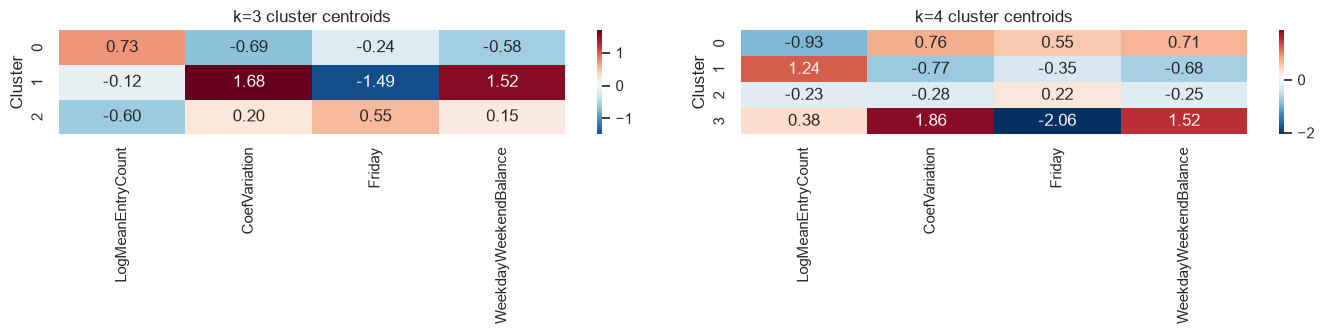

In [16]:
centres_3 = pd.DataFrame(km_3.cluster_centers_, columns=FEATURES)
centres_4 = pd.DataFrame(km_4.cluster_centers_, columns=FEATURES)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))

sns.heatmap(centres_3, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[0])
axes[0].set_title("k=3 cluster centroids")
axes[0].set_ylabel("Cluster")

sns.heatmap(centres_4, cmap="RdBu_r", center=0, annot=True, fmt=".2f", ax=axes[1])
axes[1].set_title("k=4 cluster centroids")
axes[1].set_ylabel("Cluster")

plt.tight_layout()

In [17]:
pd.crosstab(km_3.labels_, km_4.labels_,
            rownames=["k=3"], colnames=["k=4"])

k=4,0,1,2,3
k=3,,,,
0,0,103,76,0
1,15,0,2,31
2,87,0,120,0


In [18]:
distances = pd.DataFrame(km_3.transform(X_scaled), index=X_scaled.index)
distances["cluster"] = km_3.labels_

for j in range(3):
    in_cluster = distances[distances["cluster"] == j]
    closest = in_cluster.sort_values(by=j).head(10)

    print(f"\nCluster {j} (n={len(in_cluster)}):")
    print("  " + ", ".join(closest.index))


Cluster 0 (n=179):
  Golders Green, Balham, Stockwell, High Street Kensington, Southall, Tooting Bec, Hayes & Harlington, Angel, West Hampstead, Edgware Road C&H

Cluster 1 (n=48):
  Gunnersbury, Barbican, Great Portland Street, Goodge Street, Temple, Latimer Road, Chiswick Park, Heron Quays, Brentwood, Southwark

Cluster 2 (n=207):
  Stamford Brook, Pontoon Dock DLR, W Silvertown, Stratford International, Clapton, New Cross, Alperton, Kensal Green, Ruislip Manor, Northfields


## 3.6 Hierarchical clustering

ARI (k-means vs Ward): 0.485
Dendrogram linkage heights: [12.   13.53 15.84 17.55 22.53 27.37]


Ward,1,2,3
k-means,,,
0,126,44,9
1,0,8,40
2,0,182,25


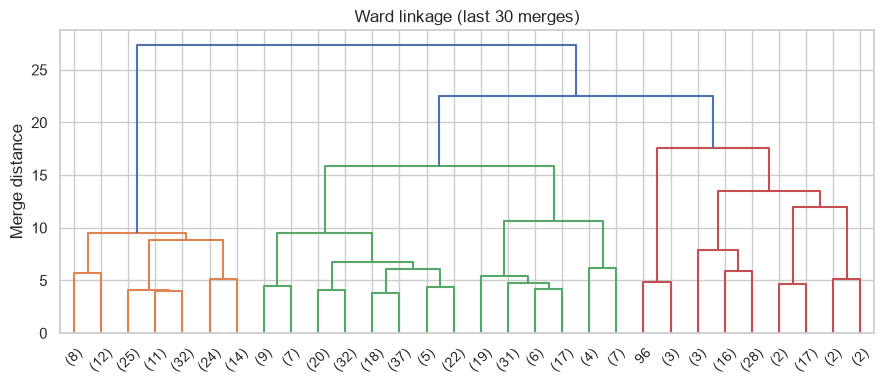

In [19]:
link = linkage(X_scaled, method="ward")
ward_labels = fcluster(link, 3, criterion="maxclust")

fig, ax = plt.subplots(figsize=(9, 4))
dendrogram(link, truncate_mode="lastp", p=30, ax=ax)
ax.set_title("Ward linkage (last 30 merges)")
ax.set_ylabel("Merge distance")
plt.tight_layout()

ari = adjusted_rand_score(km_3.labels_, ward_labels)
print("ARI (k-means vs Ward):", round(ari, 3))
print("Dendrogram linkage heights:", link[-6:, 2].round(2))

pd.crosstab(km_3.labels_, ward_labels, rownames=["k-means"], colnames=["Ward"])

## 3.7 DBSCAN

Quantiles: [0.59 0.88 1.21 1.75 4.22]


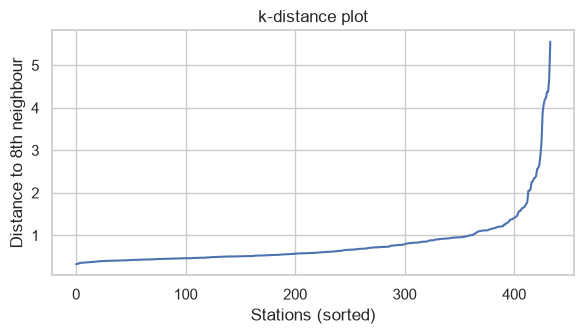

In [20]:
MIN_SAMPLES = 8

neighbours = NearestNeighbors(n_neighbors=MIN_SAMPLES)
neighbours.fit(X_scaled)
distances_to_neighbours, _ = neighbours.kneighbors(X_scaled)

# Last column is the distance to the 8th neighbour (column 0 is the point itself).
kth_distance = np.sort(distances_to_neighbours[:, -1])

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(kth_distance)
ax.set_xlabel("Stations (sorted)")
ax.set_ylabel(f"Distance to {MIN_SAMPLES}th neighbour")
ax.set_title("k-distance plot")
plt.tight_layout()

print("Quantiles:", np.round(np.quantile(kth_distance, [.5, .75, .9, .95, .99]), 2))

In [21]:
rows = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.25, 1.5]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X_scaled)

    n_noise = (labels == -1).sum()
    cluster_ids = set(labels) - {-1}

    rows.append({
        "eps": eps,
        "n_clusters": len(cluster_ids),
        "n_noise": n_noise,
        "noise_frac": n_noise / len(labels),
    })

pd.DataFrame(rows).round(3)

,eps,n_clusters,n_noise,noise_frac
0,0.30,0,434,1.000
1,0.40,3,336,0.774
2,0.50,2,203,0.468
3,0.60,1,150,0.346
4,0.80,1,83,0.191
5,1.00,1,41,0.094
6,1.25,1,26,0.060
7,1.50,1,20,0.046


In [22]:
db = DBSCAN(eps=0.8, min_samples=MIN_SAMPLES)
db.fit(X_scaled)

n_noise = (db.labels_ == -1).sum()
n_clusters = len(set(db.labels_) - {-1})
print(f"eps=0.8: {n_clusters} clusters, {n_noise} noise stations")

display(pd.crosstab(km_3.labels_, db.labels_,
                    rownames=["k-means"], colnames=["DBSCAN (-1 = noise)"]))

dense_pocket = X_scaled.index[db.labels_ == 1]
print("Dense stations:", ", ".join(dense_pocket))

eps=0.8: 1 clusters, 83 noise stations


DBSCAN (-1 = noise),-1,0
k-means,,
0,26,153
1,40,8
2,17,190


Dense stations: 


## 3.8 Results table

One row per station: cluster and label, silhouette, distance to its own centroid, date coverage and the DBSCAN noise flag.

In [23]:
station_data = pd.read_csv(f"{PROCESSED}/TfL_Data_Processed.csv")
n_dates = station_data["TravelDate"].nunique()
station_coverage = station_data.groupby("Station").size() / n_dates

cluster_names = tfl.name_clusters(centres_3)
print(cluster_names)

station_results = X_real.assign(
    Cluster=km_3.labels_,
    ClusterName=pd.Series(km_3.labels_, index=X_scaled.index).map(cluster_names),
    SilhouetteScore=silhouette_samples(X_scaled, km_3.labels_),
    CentroidDist=km_3.transform(X_scaled).min(axis=1),
    DateCoverage=station_coverage,
    DBSCANNoise=db.labels_ == -1,
)

station_results.to_csv(f"{OUTPUTS}/station_clustering_results.csv")

station_results.head()

{1: 'Weekday commuter stations', 2: 'Low volume stations', 0: 'Consistent high-volume stations'}


,MeanEntryCount,CoefVariation,Friday,WeekdayWeekendBalance,Cluster,ClusterName,SilhouetteScore,CentroidDist,DateCoverage,DBSCANNoise
Station,,,,,,,,,,
Abbey Road DLR,833.709302,0.300102,0.165609,1.754985,2,Low volume stations,0.458336,1.659291,0.980707,False
Abbey Wood,15460.488562,0.236017,0.153408,1.532354,0,Consistent high-volume stations,0.319413,0.863747,0.996785,False
Acton Central,2080.278689,0.294328,0.164737,1.549571,2,Low volume stations,0.483698,1.010152,0.993569,False
Acton Main Line,3850.225086,0.231024,0.156015,1.434396,2,Low volume stations,0.171089,0.830407,0.948553,False
Acton Town,6822.760656,0.242458,0.158009,1.383609,0,Consistent high-volume stations,-0.005186,1.052930,0.993569,False


## 3.9 Comparison with a structureless reference

Silhouette falls as dimensionality rises, so scores from feature sets of different sizes are not directly comparable. Each is therefore compared with the peak silhouette of structureless Gaussian data of the same size (20 replicates).

In [24]:
TWO_FEATURES = ["LogMeanEntryCount", "WeekdayWeekendBalance"]


def peak_silhouette(data, seed=SEED):
    """Best silhouette over k = 2 to 10, and the k that achieved it."""
    best_score, best_k = -1.0, None
    for k in range(2, 11):
        km = KMeans(n_clusters=k, init="k-means++", n_init=25, random_state=seed)
        km.fit(data)
        score = silhouette_score(data, km.labels_)
        if score > best_score:
            best_score, best_k = score, k
    return best_score, best_k


real_4, k_4 = peak_silhouette(X_scaled.values)
real_2, k_2 = peak_silhouette(X_scaled[TWO_FEATURES].values)

rng = np.random.default_rng(SEED)
null = {}
for p in [2, 4]:
    scores, ks = [], []
    for rep in range(20):
        noise = rng.standard_normal((len(X_scaled), p))
        score, k = peak_silhouette(noise, seed=SEED + rep)
        scores.append(score)
        ks.append(k)
    null[p] = (np.mean(scores), np.std(scores), pd.Series(ks).mode()[0])

print(f"{'':22s}{'peak sil':>10s}{'at k':>6s}")
print(f"{'real, 4 features':22s}{real_4:10.3f}{k_4:6d}")
print(f"{'real, 2 features':22s}{real_2:10.3f}{k_2:6d}")
print(f"{'null 4D (20 reps)':22s}{null[4][0]:10.3f}{null[4][2]:6d}   sd {null[4][1]:.3f}")
print(f"{'null 2D (20 reps)':22s}{null[2][0]:10.3f}{null[2][2]:6d}   sd {null[2][1]:.3f}")
print()
print(f"excess over chance, 4 features: {real_4 - null[4][0]:+.3f}")
print(f"excess over chance, 2 features: {real_2 - null[2][0]:+.3f}")

                        peak sil  at k
real, 4 features           0.282     3
real, 2 features           0.382     3
null 4D (20 reps)          0.192     9   sd 0.005
null 2D (20 reps)          0.351     6   sd 0.007

excess over chance, 4 features: +0.090
excess over chance, 2 features: +0.031
